In [1]:
print("Hello World")

Hello World


# **Import Necessary libraries**

In [2]:
import os
import cv2
import numpy as np
import onnxruntime as ort
from ultralytics import YOLO

## Why do we use ONNX Runtime in this project?

Here are the main reasons for choosing **ONNX Runtime** to implement this Edge AI and smart cooling system:

* **High Performance & Speed:**
Running inference using ONNX Runtime is significantly faster than using the native PyTorch library. This is crucial for maintaining a stable and high frame rate (FPS) during real-time video processing.
* **Lightweight & Low Memory:**
PyTorch is a large framework designed also for model training. Edge devices (such as Raspberry Pi, Jetson Nano, or smart controllers) have limited resources; therefore, a lightweight inference engine like ONNX Runtime utilizes minimal memory (RAM).
* **Cross-Platform Deployment:**
By converting a PyTorch model (`.pt`) into the ONNX format (`.onnx`), it can be easily deployed and run across different operating systems and programming languages (such as Python, C++, etc.) without compatibility issues.
* **Hardware Acceleration & Optimization:**
ONNX Runtime optimizes the model to efficiently leverage various hardware accelerators (CPUs, GPUs, TensorRT, OpenVINO, etc.) for maximum efficiency.

# **Model path and dirs initilalize**

We choose to use the yolov8n model for this project experiment task. The model is trained on the COCO dataset and can detect 80 different classes of objects.

In [3]:
#define model saving dir and paths
models_dir = "../models"
os.makedirs(models_dir, exist_ok=True)
onnx_path = os.path.join(models_dir, "yolo11m.onnx")
pt_path = os.path.join(models_dir, "yolo11m.pt")

In [4]:
#  check if onnx model exists
if not os.path.exists(onnx_path):
    print("ONNX model not found.")
    
    # if yolo11m.pt model doesnot exist, it download
    if not os.path.exists(pt_path):
        print("Downloading yolo11m.pt...")
        temp_model = YOLO("yolo11m.pt")  # download for exist same path
        
        # move yolo11m.pt model, models folder
        if os.path.exists("yolo11m.pt"):
            if os.path.exists(pt_path):
                os.remove(pt_path)
            os.rename("yolo11m.pt", pt_path)
            print(f"{temp_model} file successfully moved to '../models/' directory.")
            
    # load model
    model = YOLO(pt_path)

    # export to onnx format
    print("Exporting model to ONNX format...")
    model.export(format="onnx")
    
    exported_onnx_local = "yolo11m.onnx"
    exported_onnx_dir = pt_path.replace(".pt", ".onnx") 
    
    if os.path.exists(exported_onnx_local):
        if os.path.exists(onnx_path):
            os.remove(onnx_path)
        os.rename(exported_onnx_local, onnx_path)
    elif os.path.exists(exported_onnx_dir) and exported_onnx_dir != onnx_path:
        if os.path.exists(onnx_path):
            os.remove(onnx_path)
        os.rename(exported_onnx_dir, onnx_path)
        
    print(f"ONNX model successfully saved. Path: {onnx_path}")
else:
    print(f"ONNX model already exists. Path: {onnx_path}")

ONNX model already exists. Path: ../models\yolo11m.onnx


# **Start onnx runtime session**

In [5]:
session = ort.InferenceSession(onnx_path, providers=['CPUExecutionProvider'])
input_name = session.get_inputs()[0].name

print(f"onnx session ready. \nInput Name: {input_name}")

onnx session ready. 
Input Name: images


# **Input Preprocessing**

In [6]:
from IPython.display import Image, clear_output  # to display images
from matplotlib import pyplot as plt

1. **color space conversion**

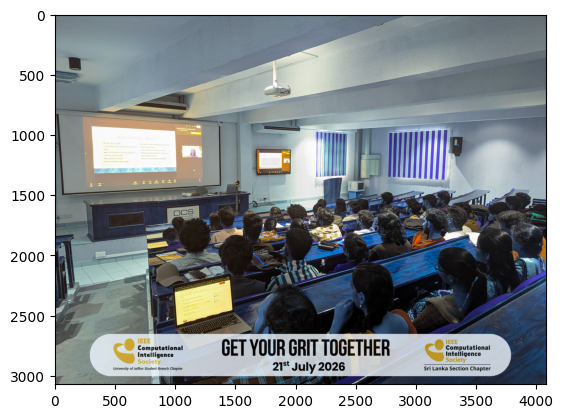

In [7]:
frame = cv2.imread("../resources/6.jpg")

#bgr to rgb conversion 
#cv2 -rgb, YOLO -rgb
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
plt.imshow(frame)

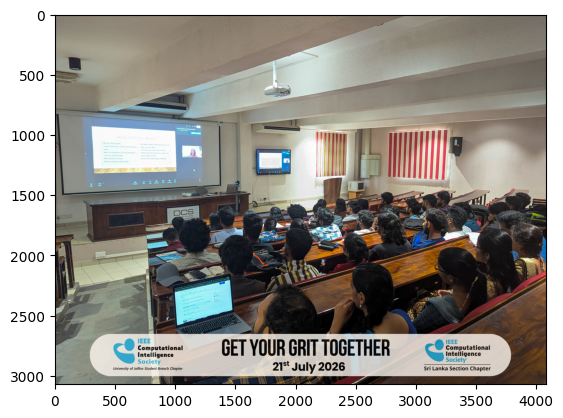

In [8]:
plt.imshow(frame_rgb)

2. **Brightness adjustment with CLAHE (Contrast Limited Adaptive Histogram Equalization)**

* why we use CLAHE for brightness adjustment? 

when we use CLAHE for brightness adjustment, it helps to enhance the contrast of the image while preventing over-amplification of noise in homogeneous areas. This is particularly useful in low-light conditions or when the image has varying lighting conditions, as it improves the visibility of features and details that may be important for object detection.

122.22058352800755


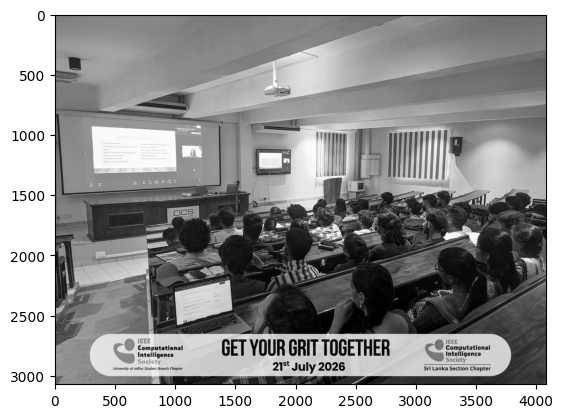

In [9]:
# convert to gray scale to get brightness level
frame_gray = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY)
brightness = np.mean(frame_gray)
plt.imshow(frame_gray, cmap="gray")
print(brightness)

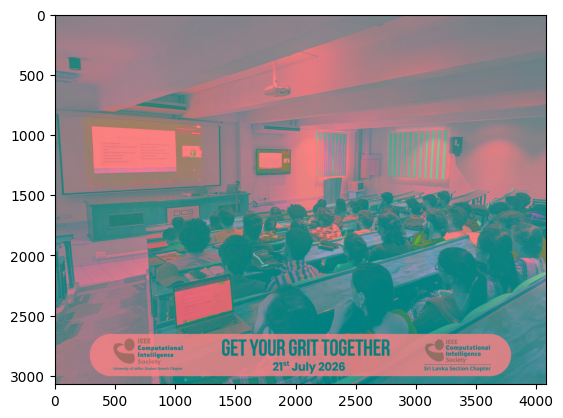

In [10]:
# CLAHE(for dark images, back row, shadow images students detection)
lab = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2LAB)
plt.imshow(lab)

In [11]:
l, a, b = cv2.split(lab)
print(l, a, b)

[[128 129 134 ... 118 115 114]
 [122 131 136 ... 117 112 114]
 [125 133 134 ... 117 115 118]
 ...
 [112 112 113 ...  68  48  51]
 [115 114 113 ...  73  60  61]
 [115 113 112 ...  68  57  55]] [[130 130 130 ... 129 129 129]
 [130 130 130 ... 129 130 129]
 [130 130 130 ... 129 129 129]
 ...
 [124 124 123 ... 136 137 137]
 [124 123 123 ... 136 137 136]
 [124 123 124 ... 136 137 137]] [[134 134 134 ... 132 132 132]
 [134 134 134 ... 132 132 132]
 [134 134 134 ... 132 132 132]
 ...
 [130 130 130 ... 141 142 141]
 [130 130 130 ... 140 141 141]
 [130 130 130 ... 141 141 141]]


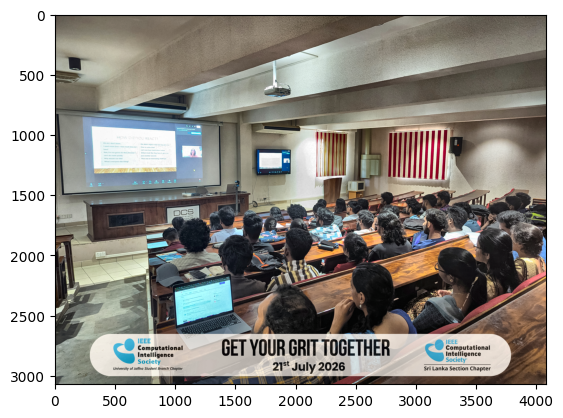

In [12]:
# initialize clahe params.
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8,8)
)

l = clahe.apply(l)

lab = cv2.merge((l,a,b))

frame_rgb_after_clahe = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
plt.imshow(frame_rgb_after_clahe)


In [13]:
# if images are darken apply CLAHE

if brightness < 80:
    lab = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8,8)
    )

    l = clahe.apply(l)

    lab = cv2.merge((l,a,b))

    frame_rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    

3. **Resize and Padding**

* Why we use padding, when resizing the image to a fixed size?

When resizing an image to a fixed size, the aspect ratio of the original image may not match the target size. This can lead to distortion or stretching of the image, which can negatively impact the performance of object detection models. To address this issue, padding is used to maintain the aspect ratio of the original image while resizing it to the desired dimensions.

In [14]:
print(frame_rgb.shape)

# get height and width
height, width = frame_rgb.shape[:2]
print(height, width)

# calculate scale ratio for padding- (New image height or width / Old image height or width)
new_shape=(640,640) # YOLO required size
ratio = min(new_shape[0]/height, new_shape[1]/width)

# Compute padding (WH padding)
new_unpad = int(round(width * ratio)), int(round(height * ratio))
dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]  # wh padding

dw /= 2  # divide padding into 2 sides
dh /= 2

(3072, 4080, 3)
3072 4080


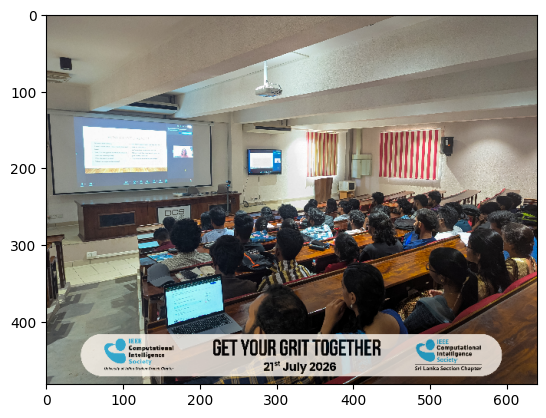

In [15]:
# resize
if shape_hw := (width, height) != new_unpad:
    im = cv2.resize(frame_rgb, new_unpad, interpolation=cv2.INTER_LINEAR)
else:
    im = frame_rgb
        
plt.imshow(im)

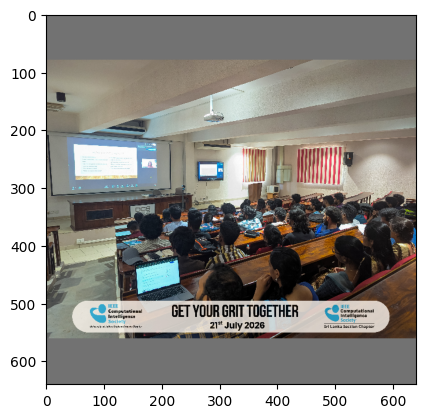

In [16]:
top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
left, right = int(round(dw - 0.1)), int(round(dw + 0.1))

# add border
im = cv2.copyMakeBorder(im, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))  

plt.imshow(im)

4. **Normalization**

for yolo11 model, the input image is normalized to a range of [0, 1] by dividing the pixel values by 255. This normalization step is important because it helps the model to converge faster during training and improves its performance during inference. Normalization also ensures that the input data is consistent with the data distribution that the model was trained on, which can lead to better generalization and accuracy.

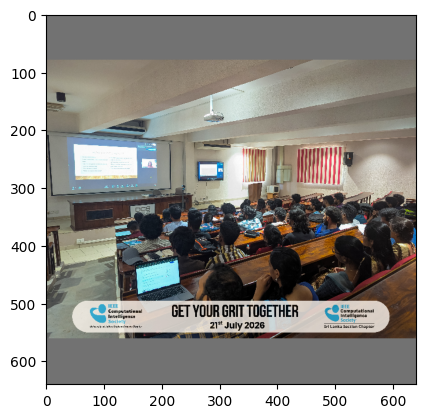

In [17]:
img = im.astype(np.float32) / 255.0
plt.imshow(img)

5. **Transpose**

for yolo11 model, the input image is transposed from the shape (height, width, channels) to (channels, height, width). This is necessary because the model expects the input in a specific format, and transposing ensures that the data is correctly structured for processing by the neural network.

In [18]:
img = np.transpose(img, (2, 0, 1))
img = np.expand_dims(img, axis=0)


## **Preprocessing Function**

Single preprocessing function is created to perform all the above preprocessing steps in a single function. This function takes an input image and returns the preprocessed image ready for inference.

In [ ]:
def preprocess(frame, new_shape=(640,640)):
    ## bgr to rgb conversion 
    #cv2 -rgb, YOLO -rgb
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # CLAHE(for dark images, back row, shadow images students detection)
    frame_gray = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY)
    brightness = np.mean(frame_gray)

    ## if images are darken apply CLAHE

    if brightness < 80:
        lab = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8,8)
        )

        l = clahe.apply(l)

        lab = cv2.merge((l,a,b))

        frame_rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    ## Resize and padding

    # get height and width
    height, width = frame_rgb.shape[:2]
    print(height, width)

    # calculate scale ratio for padding- (New image height or width / Old image height or width)
    new_shape=(640,640) # YOLO required size
    ratio = min(new_shape[0]/height, new_shape[1]/width)

    # Compute padding (WH padding)
    new_unpad = int(round(width * ratio)), int(round(height * ratio))
    dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]  # wh padding

    dw /= 2  # divide padding into 2 sides
    dh /= 2

    # resize
    if shape_hw := (width, height) != new_unpad:
        im = cv2.resize(frame_rgb, new_unpad, interpolation=cv2.INTER_LINEAR)
    else:
        im = frame_rgb

    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))

    # add border
    im = cv2.copyMakeBorder(im, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))  
    
    # Normalization and Transpose
    img = im.astype(np.float32) / 255.0
    img = np.transpose(img, (2, 0, 1))
    img = np.expand_dims(img, axis=0)
    
    return img, ratio, (dw, dh)
    

3072 4080
🔹 Detected Students/People : 32
🔹 AC Unit State           : ON


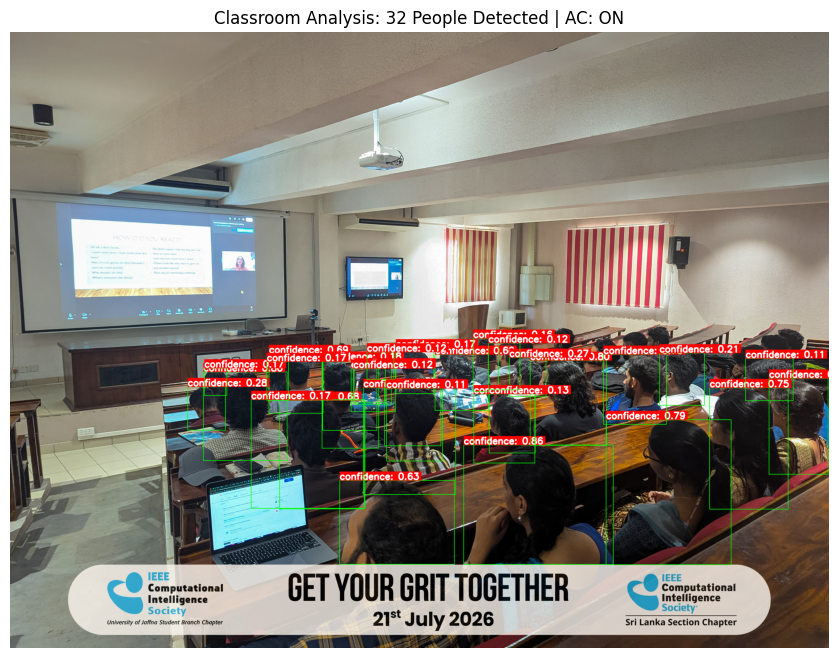

In [79]:


image_path = "../resources/6.jpg"  # ඔබේ පින්තූරයේ path එක
frame = cv2.imread(image_path)

if frame is not None:
    h_orig, w_orig = frame.shape[:2]
    
    # 1. Preprocess
    input_tensor, r, (dw, dh) = preprocess(frame)
    
    # 2. Inference
    outputs = session.run(None, {input_name: input_tensor})
    preds = np.squeeze(outputs[0]).T
    
    conf_threshold = 0.10 
    nms_threshold = 0.75   # එකම පුද්ගලයා මත බොක්ස් අධිපති වීම වැළැක්වීමට
    
    boxes = []
    confidences = []
    class_ids = []
    
    for row in preds:
        classes_scores = row[4:]
        max_score = np.max(classes_scores)
        class_id = np.argmax(classes_scores)
        
        if class_id == 0 and max_score > conf_threshold:
            cx, cy, bw, bh = row[0], row[1], row[2], row[3]
            
            # Letterbox කෝඩිනේට්ස් ඔරිජිනල් සයිස් එකට හැරවීම
            x1 = int((cx - bw/2 - dw) / r)
            y1 = int((cy - bh/2 - dh) / r)
            x2 = int((cx + bw/2 - dw) / r)
            y2 = int((cy + bh/2 - dh) / r)
            
            w_box = x2 - x1
            h_box = y2 - y1
            
            boxes.append([x1, y1, w_box, h_box])
            confidences.append(float(max_score))
            class_ids.append(class_id)

    # 3. Non-Maximum Suppression (NMS) යෙදීම මඟින් අතිරික්ත බොක්ස් ඉවත් කිරීම
    indices = cv2.dnn.NMSBoxes(boxes, confidences, conf_threshold, nms_threshold)
    
    person_count = 0
    if len(indices) > 0:
        for i in indices.flatten():
            person_count += 1
            x, y, w_box, h_box = boxes[i]
            conf = confidences[i]
            
            # Image සීමාවන් ඇතුළේ තබාගැනීම
            x1 = max(0, x)
            y1 = max(0, y)
            x2 = min(w_orig, x + w_box)
            y2 = min(h_orig, y + h_box)
            
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)

            # 2. Text එක සකස් කිරීම (උදා: 0.85)
            label = f"confidence: {conf:.2f}"
            
            # 3. Text එකේ ප්‍රමාණය ලබා ගැනීම (පසුබිම් කොටුව ඇඳීමට)
            font_scale = 1.5
            font_thickness = 5
            (text_width, text_height), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, font_thickness)
            
            # 4. පසුබිම් කොටුව සඳහා කෝඩිනේට්ස් සකස් කිරීම (ටෙක්ස්ට් එකට ටිකක් උඩින්)
            box_x1 = x1
            box_y1 = y1 - text_height - 10
            box_x2 = x1 + text_width + 5
            box_y2 = y1
            
            # Image සීමාවෙන් පිටතට නොයාමට clipping
            box_y1 = max(0, box_y1)
            
            # 5. කළු පාට පසුබිම් කොටුව ඇඳීම (Filled rectangle - thickness=-1)
            cv2.rectangle(frame, (box_x1, box_y1), (box_x2, box_y2), (0, 0, 255), -1)
            
            # 6. දැන් ටෙක්ස්ට් එක කළු කොටුව මත ලිවීම (සුදු පාටින් - (255, 255, 255))
            cv2.putText(
                frame, 
                label, 
                (x1, y1 - 5), 
                cv2.FONT_HERSHEY_SIMPLEX, 
                font_scale,
                (255, 255, 255),   # අකුරේ පාට සුදු (White)
                font_thickness,
                cv2.LINE_AA
            )

    # 4. Results
    ac_state = "ON" if person_count > 0 else "OFF"
    occupancy = "HIGH" if person_count > 20 else ("MEDIUM" if person_count > 5 else "LOW")
    
    print(f"🔹 Detected Students/People : {person_count}")
    print(f"🔹 AC Unit State           : {ac_state}")
    
    # පෙන්වීම
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 8))
    plt.imshow(frame_rgb)
    plt.axis('off')
    plt.title(f"Classroom Analysis: {person_count} People Detected | AC: {ac_state}")
    plt.show()

In [22]:
''''
import cv2
import numpy as np
import time
import IPython.display
from PIL import Image

# වෙබ්කැම් එක (0) හෝ වීඩියෝ ෆයිල් එකක් ලබාදීම
video_path = 0  
cap = cv2.VideoCapture(video_path)

# 🛠️ කැමරාව සම්පූර්ණයෙන්ම ඔන් වී සූදානම් වීමට තත්පර 2ක් ලබා දීම
print("📷 Initializing Camera...")
time.sleep(2.0)

print("🚀 Running Live Experiment inside Jupyter Notebook... (Stop කිරීමට ⏹️ බොත්තම ඔබන්න)")

try:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            print("⚠️ Frame read failed. Retrying...")
            time.sleep(0.5)
            continue
            
        h, w, _ = frame.shape
        input_tensor = preprocess_frame(frame)
        
        # ONNX Inference ක්‍රියාවලිය
        outputs = session.run(None, {input_name: input_tensor})
        preds = np.squeeze(outputs[0]).T
        
        person_count = 0
        conf_threshold = 0.50
        
        for row in preds:
            classes_scores = row[4:]
            max_score = np.max(classes_scores)
            class_id = np.argmax(classes_scores)
            
            if class_id == 0 and max_score > conf_threshold:
                person_count += 1
                
                # Bounding Box coordinates
                cx, cy, bw, bh = row[0], row[1], row[2], row[3]
                x1 = int((cx - bw/2) * w / 640)
                y1 = int((cy - bh/2) * h / 640)
                x2 = int((cx + bw/2) * w / 640)
                y2 = int((cy + bh/2) * h / 640)
                
                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)

        # Smart Cooling Logic
        ac_state = "ON" if person_count > 0 else "OFF"
        occupancy = "HIGH" if person_count > 20 else ("MEDIUM" if person_count > 5 else "LOW")
        
        text = f"People: {person_count} | Occupancy: {occupancy} | AC: {ac_state}"
        cv2.putText(frame, text, (30, 50), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
        
        # OpenCV BGR රූපය RGB වෙත හරවා PIL Image එකක් බවට පත් කිරීම
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(frame_rgb)
        
        # නෝට්බුක් එක ඇතුළේ ෆ්‍රේම් එක තත්‍ය කාලීනව අප්ඩේට් කර පෙන්වීම
        IPython.display.clear_output(wait=True)
        display(pil_img)

except KeyboardInterrupt:
    print("🛑 Experiment stopped by user.")

finally:
    cap.release()
    cv2.destroyAllWindows()
'''    

'\'\nimport cv2\nimport numpy as np\nimport time\nimport IPython.display\nfrom PIL import Image\n\n# වෙබ්කැම් එක (0) හෝ වීඩියෝ ෆයිල් එකක් ලබාදීම\nvideo_path = 0  \ncap = cv2.VideoCapture(video_path)\n\n# 🛠️ කැමරාව සම්පූර්ණයෙන්ම ඔන් වී සූදානම් වීමට තත්පර 2ක් ලබා දීම\nprint("📷 Initializing Camera...")\ntime.sleep(2.0)\n\nprint("🚀 Running Live Experiment inside Jupyter Notebook... (Stop කිරීමට ⏹️ බොත්තම ඔබන්න)")\n\ntry:\n    while cap.isOpened():\n        ret, frame = cap.read()\n        if not ret:\n            print("⚠️ Frame read failed. Retrying...")\n            time.sleep(0.5)\n            continue\n            \n        h, w, _ = frame.shape\n        input_tensor = preprocess_frame(frame)\n        \n        # ONNX Inference ක්\u200dරියාවලිය\n        outputs = session.run(None, {input_name: input_tensor})\n        preds = np.squeeze(outputs[0]).T\n        \n        person_count = 0\n        conf_threshold = 0.50\n        \n        for row in preds:\n            classes_scores = row[

In [23]:
'''  
import cv2
import numpy as np
import time
import IPython.display
from PIL import Image

# 🛠️ Windows වලදී cv2.CAP_DSHOW යොදා ගැනීමෙන් කැමරා සම්බන්ධතා දෝෂ මඟහරවා ගත හැක
video_path = 0  
cap = cv2.VideoCapture(video_path, cv2.CAP_DSHOW)

print("📷 Initializing Camera...")
time.sleep(2.0)

if not cap.isOpened():
    print("❌ Error: Camera could not be opened. Please check permissions.")
else:
    print("🚀 Running Live Experiment inside Jupyter Notebook... (Stop කිරීමට ⏹️ බොත්තම ඔබන්න)")

try:
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret or frame is None:
            print("⚠️ Frame read failed. Retrying...")
            time.sleep(0.5)
            continue
            
        h, w, _ = frame.shape
        input_tensor = preprocess_frame(frame)
        
        # ONNX Inference ක්‍රියාවලිය
        outputs = session.run(None, {input_name: input_tensor})
        preds = np.squeeze(outputs[0]).T
        
        person_count = 0
        conf_threshold = 0.50
        
        for row in preds:
            classes_scores = row[4:]
            max_score = np.max(classes_scores)
            class_id = np.argmax(classes_scores)
            
            if class_id == 0 and max_score > conf_threshold:
                person_count += 1
                
                # Bounding Box coordinates
                cx, cy, bw, bh = row[0], row[1], row[2], row[3]
                x1 = int((cx - bw/2) * w / 640)
                y1 = int((cy - bh/2) * h / 640)
                x2 = int((cx + bw/2) * w / 640)
                y2 = int((cy + bh/2) * h / 640)
                
                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)

        # Smart Cooling Logic
        ac_state = "ON" if person_count > 0 else "OFF"
        occupancy = "HIGH" if person_count > 20 else ("MEDIUM" if person_count > 5 else "LOW")
        
        text = f"People: {person_count} | Occupancy: {occupancy} | AC: {ac_state}"
        cv2.putText(frame, text, (30, 50), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)
        
        # OpenCV BGR රූපය RGB වෙත හරවා PIL Image එකක් බවට පත් කිරීම
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        pil_img = Image.fromarray(frame_rgb)
        
        # නෝට්බුක් එක ඇතුළේ ෆ්‍රේම් එක තත්‍ය කාලීනව අප්ඩේට් කර පෙන්වීම
        IPython.display.clear_output(wait=True)
        display(pil_img)

except KeyboardInterrupt:
    print("🛑 Experiment stopped by user.")

finally:
    cap.release()
    cv2.destroyAllWindows()
'''      

'  \nimport cv2\nimport numpy as np\nimport time\nimport IPython.display\nfrom PIL import Image\n\n# 🛠️ Windows වලදී cv2.CAP_DSHOW යොදා ගැනීමෙන් කැමරා සම්බන්ධතා දෝෂ මඟහරවා ගත හැක\nvideo_path = 0  \ncap = cv2.VideoCapture(video_path, cv2.CAP_DSHOW)\n\nprint("📷 Initializing Camera...")\ntime.sleep(2.0)\n\nif not cap.isOpened():\n    print("❌ Error: Camera could not be opened. Please check permissions.")\nelse:\n    print("🚀 Running Live Experiment inside Jupyter Notebook... (Stop කිරීමට ⏹️ බොත්තම ඔබන්න)")\n\ntry:\n    while cap.isOpened():\n        ret, frame = cap.read()\n        if not ret or frame is None:\n            print("⚠️ Frame read failed. Retrying...")\n            time.sleep(0.5)\n            continue\n            \n        h, w, _ = frame.shape\n        input_tensor = preprocess_frame(frame)\n        \n        # ONNX Inference ක්\u200dරියාවලිය\n        outputs = session.run(None, {input_name: input_tensor})\n        preds = np.squeeze(outputs[0]).T\n        \n        person